# Scoring crédit : prédire le défaut de paiement avec XGBoost et SHAP

**Question métier :** une banque reçoit une demande de crédit. Doit-elle l'accorder ?

On construit un modèle qui estime la **probabilité de défaut** d'un client, on fixe un **seuil de décision** qui minimise les pertes de la banque, puis on **explique** chaque décision avec SHAP (obligatoire en pratique : un client refusé a le droit de savoir pourquoi).

**Plan**
1. Les données
2. Exploration rapide
3. Modèle de référence : régression logistique
4. XGBoost
5. Choisir le seuil avec un coût métier
6. Évaluation finale sur des données jamais vues
7. Expliquer le modèle avec SHAP
8. Limites et pistes

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # pour importer le dossier src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

from src.data import load_dataset
from src.model import (SEED, COST_FN, COST_FP, make_logreg, make_xgb, gini,
                       oof_proba, business_cost, best_threshold)

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Les données

**German Credit** (UCI, licence CC BY 4.0) : 1 000 demandes de crédit d'une banque allemande, 20 variables (compte courant, durée, montant, épargne, emploi...) et une cible : le client a-t-il été un bon ou un mauvais payeur ?

Le fichier est déjà dans `data/` ; s'il manque, `load_dataset()` le télécharge depuis l'UCI, sans compte.

> **Choix éthique :** on retire la *situation personnelle* (qui mélange sexe et statut marital) et le statut de *travailleur étranger*. Un modèle de crédit ne doit pas discriminer sur ces critères (en Europe, c'est aussi une exigence réglementaire).

In [2]:
X, y = load_dataset(drop_sensitive=True)
print(f"{X.shape[0]} clients, {X.shape[1]} variables explicatives")
print(f"Taux de défaut : {y.mean():.0%}")
X.head()

1000 clients, 18 variables explicatives
Taux de défaut : 30%


,statut_compte,duree_mois,historique_credit,objet_credit,montant,epargne,anciennete_emploi,taux_effort,autres_debiteurs,anciennete_residence,patrimoine,age,autres_credits,logement,nb_credits_banque,emploi,nb_personnes_charge,telephone
0,< 0 DM,6,compte critique,radio/TV,1169,inconnue / aucune,>= 7 ans,4,aucun,4,immobilier,67,aucun,propriétaire,2,employé qualifié,1,oui
1,0-200 DM,48,crédits en cours à jour,radio/TV,5951,< 100 DM,1-4 ans,2,aucun,2,immobilier,22,aucun,propriétaire,1,employé qualifié,1,non
2,pas de compte,12,compte critique,études,2096,< 100 DM,4-7 ans,2,aucun,3,immobilier,49,aucun,propriétaire,1,non qualifié résident,2,non
3,< 0 DM,42,crédits en cours à jour,mobilier,7882,< 100 DM,4-7 ans,2,garant,4,épargne / assurance vie,45,aucun,logé gratuitement,1,employé qualifié,2,non
4,< 0 DM,24,retards passés,voiture neuve,4870,< 100 DM,1-4 ans,3,aucun,4,inconnu / aucun,53,aucun,logé gratuitement,2,employé qualifié,2,non


## 2. Exploration rapide

Quelques variables qui, intuitivement, devraient compter : le solde du compte courant, la durée et le montant du crédit.

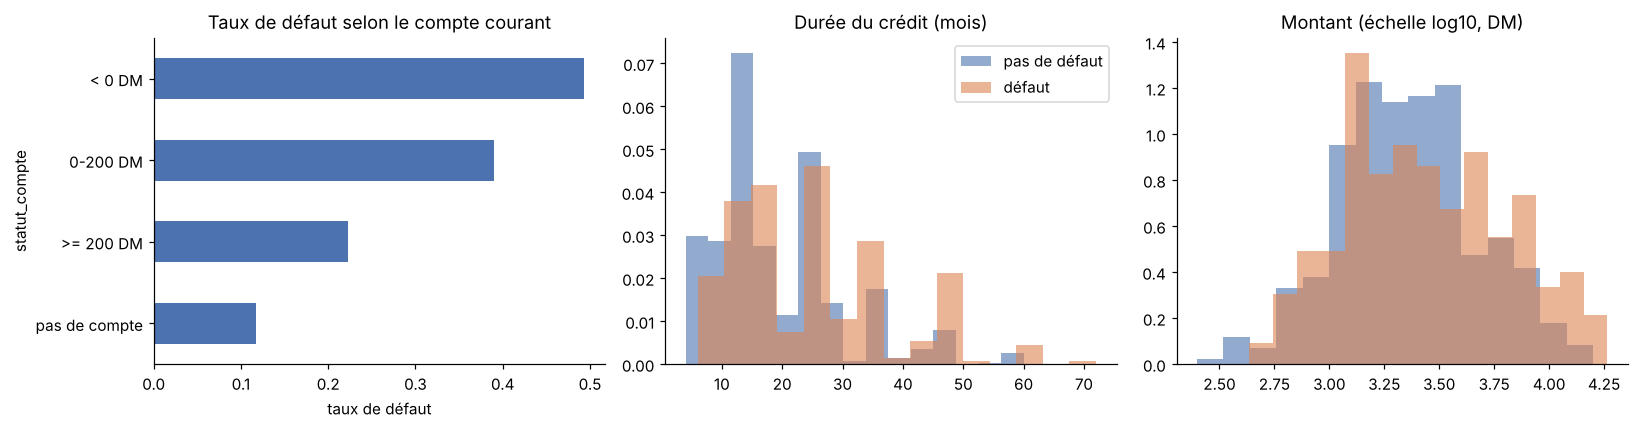

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

taux = y.groupby(X["statut_compte"], observed=True).mean().sort_values()
taux.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Taux de défaut selon le compte courant"); axes[0].set_xlabel("taux de défaut")

for lab, col in [(0, "#4C72B0"), (1, "#DD8452")]:
    axes[1].hist(X.loc[y == lab, "duree_mois"], bins=15, alpha=.6, color=col,
                 label="défaut" if lab else "pas de défaut", density=True)
axes[1].set_title("Durée du crédit (mois)"); axes[1].legend()

for lab, col in [(0, "#4C72B0"), (1, "#DD8452")]:
    axes[2].hist(np.log10(X.loc[y == lab, "montant"]), bins=15, alpha=.6, color=col, density=True)
axes[2].set_title("Montant (échelle log10, DM)")

plt.tight_layout(); plt.savefig(FIG / "exploration.png", bbox_inches="tight"); plt.show()

**Ce qu'on retient :** un client sans compte courant ou avec un solde positif fait beaucoup moins défaut qu'un client à découvert. Les crédits longs sont plus risqués. Le jeu est **déséquilibré** (70 % / 30 %) : l'*accuracy* serait trompeuse, on utilisera le **Gini** (= 2 × AUC − 1), la métrique standard des équipes risque.

On met de côté 20 % des clients comme **jeu de test**, qu'on ne regardera qu'à la toute fin.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(len(X_tr), "clients pour entraîner,", len(X_te), "pour tester")

800 clients pour entraîner, 200 pour tester


## 3. Modèle de référence : régression logistique

C'est le modèle historique des banques (simple, lisible). Tout modèle plus complexe doit faire **mieux** que lui pour être justifié. On l'évalue par **validation croisée à 5 plis** sur le jeu d'entraînement.

In [5]:
logreg = make_logreg(X_tr)
p_lr = oof_proba(logreg, X_tr, y_tr)
print(f"Régression logistique — Gini (validation croisée) : {gini(y_tr, p_lr):.3f}")

Régression logistique — Gini (validation croisée) : 0.531


## 4. XGBoost

Le *gradient boosting* empile des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents. Il capte les **non-linéarités** et les **interactions** (par ex. « crédit long *et* pas d'épargne ») que la logistique rate.

Réglages volontairement prudents (arbres peu profonds, apprentissage lent) car 800 lignes, c'est peu : le risque principal est le **surapprentissage**.

XGBoost — Gini (validation croisée) : 0.580


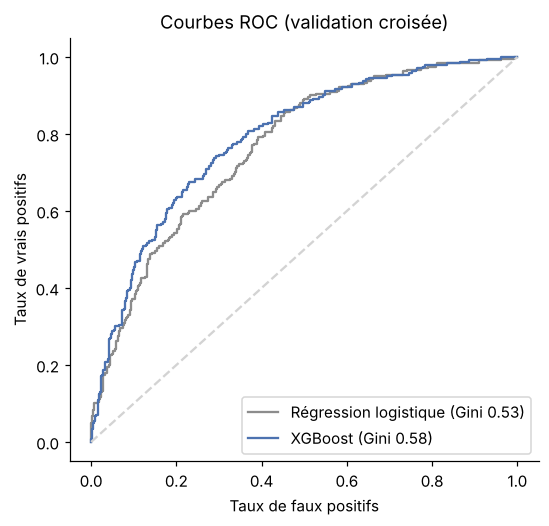

In [6]:
xgb = make_xgb(y_tr)
p_xgb = oof_proba(xgb, X_tr, y_tr)
print(f"XGBoost — Gini (validation croisée) : {gini(y_tr, p_xgb):.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p, c in [("Régression logistique", p_lr, "#8C8C8C"), ("XGBoost", p_xgb, "#4C72B0")]:
    fpr, tpr, _ = roc_curve(y_tr, p)
    ax.plot(fpr, tpr, color=c, label=f"{name} (Gini {gini(y_tr, p):.2f})")
ax.plot([0, 1], [0, 1], "--", color="lightgray")
ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC (validation croisée)"); ax.legend(loc="lower right")
plt.savefig(FIG / "roc.png", bbox_inches="tight"); plt.show()

## 5. Choisir le seuil avec un coût métier

Le modèle donne une probabilité ; la banque, elle, doit dire **oui ou non**. Le seuil de 0,5 par défaut n'a aucune raison d'être le bon, car les erreurs ne coûtent pas pareil :

| Erreur | Coût |
|---|---|
| Accorder un crédit à un client qui fera défaut | **5** (on perd le capital) |
| Refuser un bon client | **1** (on perd les intérêts) |

C'est la matrice de coût fournie avec le jeu de données. On cherche le seuil qui minimise le coût moyen, **sur les prédictions de validation croisée** (pas sur le test, sinon on tricherait).

Seuil optimal : 0.21  ->  coût moyen 0.521 par dossier
Avec le seuil 0,5 : coût moyen 0.656


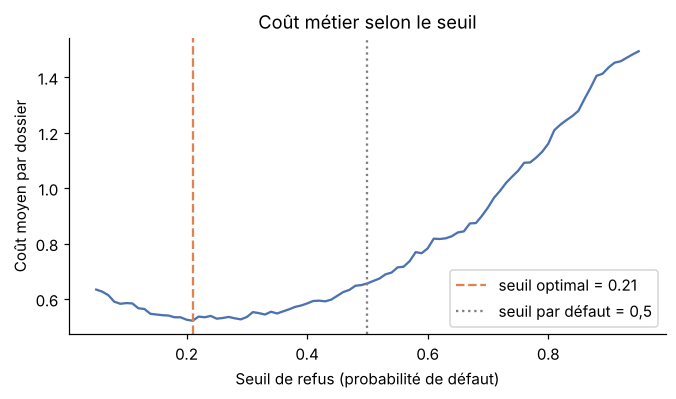

In [7]:
seuil, cout_min, grille, couts = best_threshold(y_tr, p_xgb)
print(f"Seuil optimal : {seuil:.2f}  ->  coût moyen {cout_min:.3f} par dossier")
print(f"Avec le seuil 0,5 : coût moyen {business_cost(y_tr, p_xgb, 0.5):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grille, couts, color="#4C72B0")
ax.axvline(seuil, ls="--", color="#DD8452", label=f"seuil optimal = {seuil:.2f}")
ax.axvline(0.5, ls=":", color="gray", label="seuil par défaut = 0,5")
ax.set_xlabel("Seuil de refus (probabilité de défaut)"); ax.set_ylabel("Coût moyen par dossier")
ax.set_title("Coût métier selon le seuil"); ax.legend()
plt.savefig(FIG / "cout_seuil.png", bbox_inches="tight"); plt.show()

## 6. Évaluation finale sur le jeu de test

On réentraîne les modèles sur tout le jeu d'entraînement, puis on les évalue **une seule fois** sur les 200 clients mis de côté. On compare aussi à la stratégie naïve « accepter tout le monde ».

In [8]:
seuil_lr, *_ = best_threshold(y_tr, p_lr)
logreg.fit(X_tr, y_tr); xgb.fit(X_tr, y_tr)
pt_lr = logreg.predict_proba(X_te)[:, 1]
pt_xgb = xgb.predict_proba(X_te)[:, 1]

resultats = pd.DataFrame({
    "Gini": [np.nan, gini(y_te, pt_lr), gini(y_te, pt_xgb)],
    "Coût moyen / dossier": [COST_FN * y_te.mean(),
                             business_cost(y_te, pt_lr, seuil_lr),
                             business_cost(y_te, pt_xgb, seuil)],
}, index=["Accepter tout le monde", "Régression logistique", "XGBoost"]).round(3)
resultats

,Gini,Coût moyen / dossier
Accepter tout le monde,NaN,1.500
Régression logistique,0.609,0.595
XGBoost,0.626,0.540


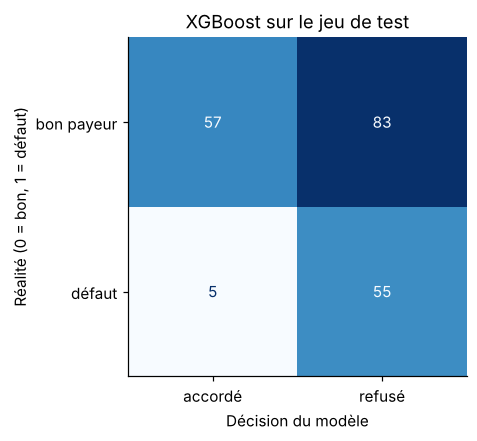

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_te, (pt_xgb >= seuil).astype(int), display_labels=["accordé", "refusé"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Décision du modèle"); ax.set_ylabel("Réalité (0 = bon, 1 = défaut)")
ax.set_yticklabels(["bon payeur", "défaut"])
ax.set_title("XGBoost sur le jeu de test")
plt.savefig(FIG / "matrice_confusion.png", bbox_inches="tight"); plt.show()

**Lecture :** XGBoost divise le coût par près de 3 par rapport à « accepter tout le monde », et fait mieux que la régression logistique. L'écart entre les deux reste modeste : sur 1 000 lignes c'est normal, et c'est un point honnête à mentionner en entretien.

Le seuil est bas : le modèle refuse dès que le risque estimé dépasse ~20 %. C'est logique, puisqu'un défaut coûte 5 fois plus qu'un refus.

## 7. Expliquer le modèle avec SHAP

XGBoost est une « boîte noire ». **SHAP** (valeurs de Shapley, issues de la théorie des jeux) répartit la prédiction entre les variables : pour chaque client, de combien chaque variable a poussé le risque vers le haut ou vers le bas.

### 7a. Vue globale : quelles variables comptent ?

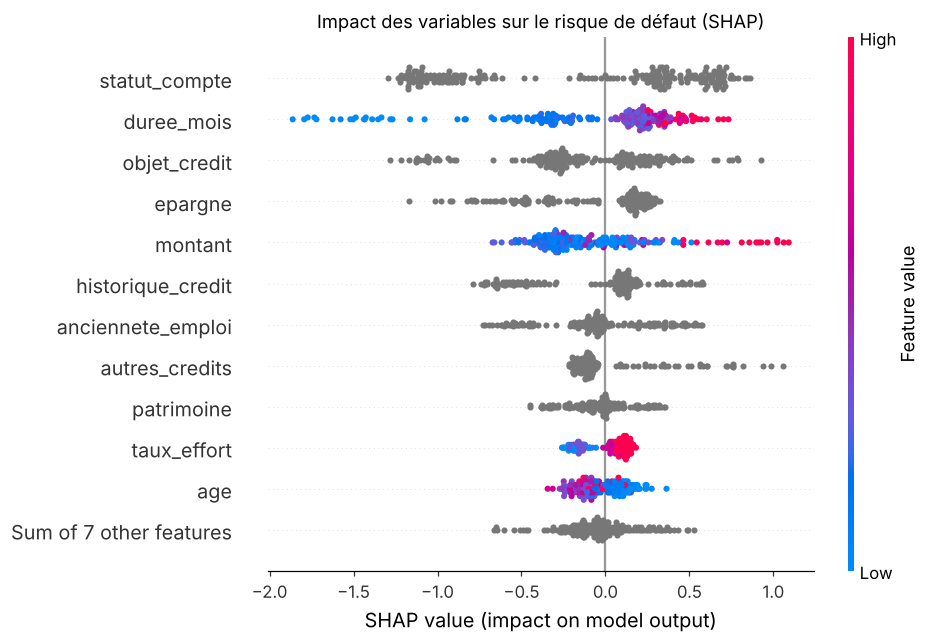

In [10]:
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_te)

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Impact des variables sur le risque de défaut (SHAP)")
plt.savefig(FIG / "shap_global.png", bbox_inches="tight"); plt.show()

Chaque point est un client (les variables catégorielles sont en gris, car elles n'ont pas d'ordre « faible/élevé »). À droite = la variable **augmente** le risque, à gauche = elle le **diminue**. Le statut du compte courant arrive largement en tête, suivi de la durée, de l'objet du crédit, de l'épargne et du montant. C'est cohérent avec l'exploration et avec l'intuition d'un banquier : bon signe pour la crédibilité du modèle.

### 7b. Vue locale : pourquoi ce client est-il refusé ?

C'est l'usage réel en banque : justifier une décision individuelle.

Probabilité de défaut estimée : 94%  ->  REFUSÉ


,client
statut_compte,< 0 DM
duree_mois,45
historique_credit,aucun crédit / tout remboursé
objet_credit,professionnel
montant,11816
epargne,< 100 DM
anciennete_emploi,>= 7 ans
taux_effort,2
autres_debiteurs,aucun
anciennete_residence,4


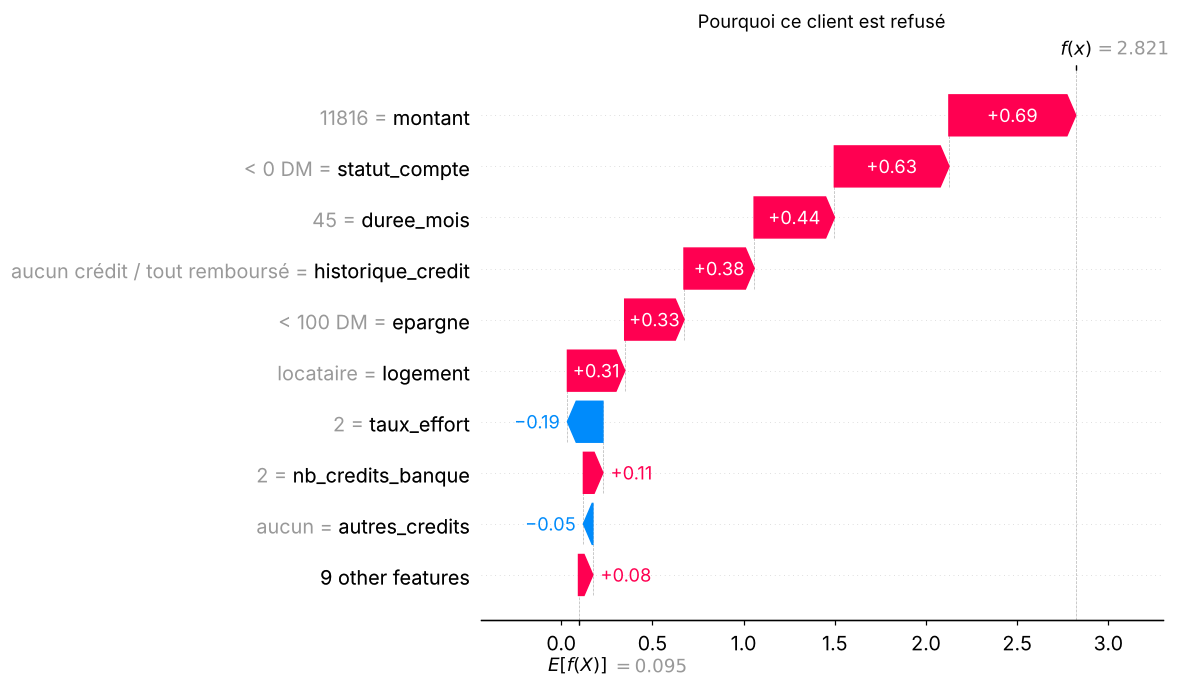

In [11]:
i = int(np.argmax(pt_xgb))  # le client jugé le plus risqué du jeu de test
print(f"Probabilité de défaut estimée : {pt_xgb[i]:.0%}  ->  {'REFUSÉ' if pt_xgb[i] >= seuil else 'ACCORDÉ'}")
display(X_te.iloc[[i]].T.rename(columns=lambda _: "client"))

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title("Pourquoi ce client est refusé")
plt.savefig(FIG / "shap_client.png", bbox_inches="tight"); plt.show()

Le graphique part du risque moyen (en bas) et ajoute la contribution de chaque variable jusqu'au score final. On peut en tirer une phrase pour le client, par exemple : *« compte courant à découvert, crédit long et montant élevé »*.

> Note : pour XGBoost, SHAP travaille en *log-odds* (l'échelle interne du modèle), pas directement en probabilité. Le sens des contributions reste le même.

## 8. Limites et pistes

**Limites**
- 1 000 clients seulement, données des années 1990 : le modèle sert à démontrer une méthode, pas à être mis en production.
- La matrice de coût 5/1 est une convention ; en vrai elle se calcule à partir de la perte en cas de défaut (LGD) et de la marge.
- Retirer les variables sensibles ne suffit pas toujours : d'autres variables peuvent leur être corrélées. Un audit d'équité serait l'étape suivante.

**Pistes pour aller plus loin**
- Refaire l'étude sur **Home Credit** (300 000 clients, Kaggle) pour passer à l'échelle.
- Optimiser les hyperparamètres avec **Optuna** en validation croisée.
- **Calibrer** les probabilités (isotonic) pour qu'elles soient interprétables comme des PD réglementaires (Bâle).
- Construire une **grille de score** (points par variable) à partir de la logistique, le format utilisé par les banques.
- Déployer une petite démo **Streamlit** : on saisit un client, on obtient la décision et son explication SHAP.